In [109]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

mall = pd.read_csv(r"C:\Users\SuNi\Downloads\Mall_Customers.csv")
mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [110]:
print(mall.shape)
mall.info()

(200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [111]:
mall.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [112]:
mall.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [113]:
mall.duplicated().sum()

np.int64(0)

In [114]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

X = mall[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
mall['cluster'] = kmeans.fit_predict(X_scaled)
mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


In [115]:
score = mall.groupby('cluster')['Spending Score (1-100)'].mean().sort_values()
mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


In [116]:
label_mapping = {
    score.index[0]: 'Low Spenders',
    score.index[1]: 'Medium Spenders',
    score.index[2]: 'High Spenders'
}

mall['Spending'] = mall['cluster'].map(label_mapping)
mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,Spending
0,1,Male,19,15,39,0,Medium Spenders
1,2,Male,21,15,81,0,Medium Spenders
2,3,Female,20,16,6,0,Medium Spenders
3,4,Female,23,16,77,0,Medium Spenders
4,5,Female,31,17,40,0,Medium Spenders


In [117]:
Segment_summary = mall.groupby('Spending').agg(
    Coustomer_Count = ('CustomerID', 'count'),
    Avg_Age = ('Age', 'mean'),
    Avg_Income_K = ('Annual Income (k$)', 'mean'),
    Avg_Spending_Score  = ('Spending Score (1-100)', 'mean')
)

print(Segment_summary.reindex(['Low Spenders', 'Medium Spenders', 'High Spenders']))

                 Coustomer_Count    Avg_Age  Avg_Income_K  Avg_Spending_Score
Spending                                                                     
Low Spenders                  91  51.274725     61.802198           34.208791
Medium Spenders               68  25.838235     42.750000           53.647059
High Spenders                 41  32.853659     87.341463           79.975610


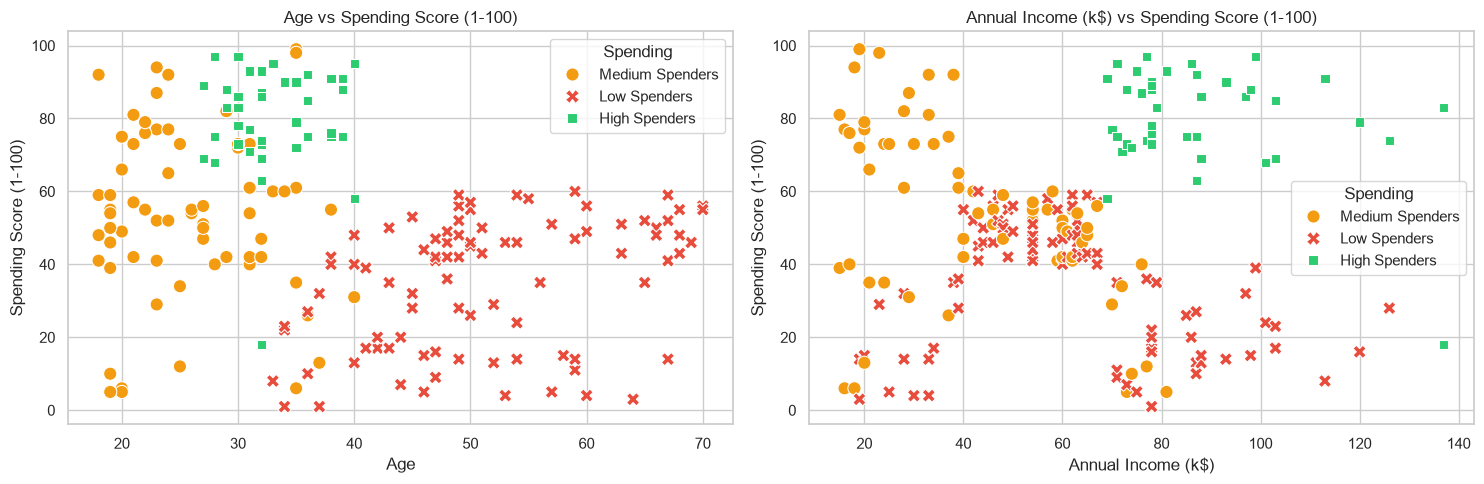

In [118]:
sns.set_theme(style = 'whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = {'Low Spenders': '#e74c3c', 'Medium Spenders': '#f39c12', 'High Spenders': '#2ecc71'}

sns.scatterplot(data=mall, x='Age', y='Spending Score (1-100)', hue='Spending', palette=palette, style='Spending',
                s=90, ax=axes[0])
axes [0].set_title('Age vs Spending Score (1-100)')

sns.scatterplot(data=mall, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Spending', palette=palette, style='Spending',
                s=90, ax=axes[1]) 
axes [1].set_title('Annual Income (k$) vs Spending Score (1-100)')
plt.tight_layout()
plt.show()

In [119]:
pca = PCA(n_components=2)
pts = pca.fit_transform(X_scaled)
cen = pca.transform(kmeans.cluster_centers_)
print("Explained Variance:", pca.explained_variance_ratio_.round(3))
print("Total Variance:", pca.explained_variance_ratio_.sum().round(3))

Explained Variance: [0.443 0.333]
Total Variance: 0.776


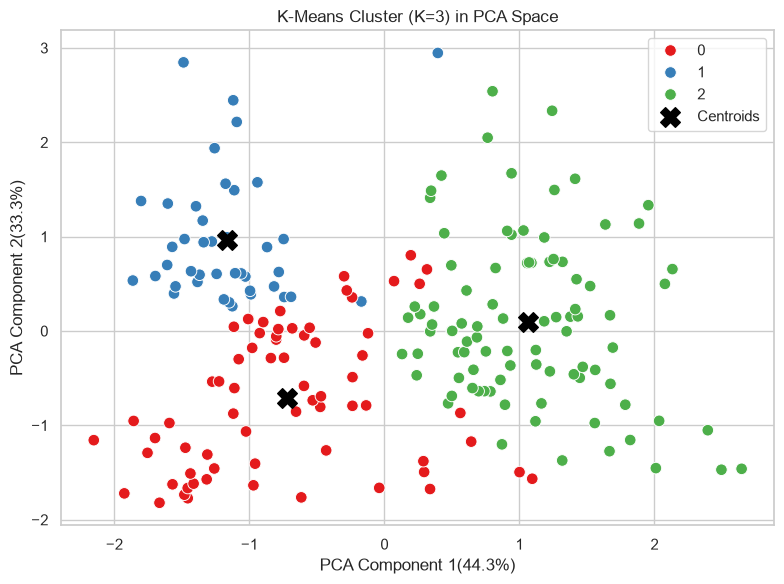

In [120]:
mall['PCA1'] = pts[:,0]
mall['PCA2'] = pts[:,1]

centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,6))
sns.scatterplot(x='PCA1', y='PCA2', hue = 'cluster', data = mall, palette='Set1', s=70)
plt.scatter(centroids_pca[:,0], centroids_pca[:,1], color = 'black', s=200, marker='X', label= 'Centroids')
plt.title('K-Means Cluster (K=3) in PCA Space')
plt.xlabel(f'PCA Component 1({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA Component 2({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend()
plt.tight_layout()
plt.show()